# MScFE 660 risk management
# # group work project 2 — methodology description and model development

| | |
|---|---|
| **Group** | 16491 |
| **Student A** | Hitesh Sanjay Nanwani |
| **Student B** | Frank Ndhlovu |
| **Student C** | Julien Haroun |

**Reference Paper:** Alvi, Danish A. *Application of Probabilistic Graphical Models in Forecasting Crude Oil Price.* UCL Dissertation, 2018. https://arxiv.org/abs/1804.10869



In [ ]:
# Install required libraries (Google Colab)
!pip install -q hmmlearn pgmpy yfinance pandas_datareader seaborn


[notice] A new release of pip is available: 25.3 -> 26.1.2
[notice] To update, run: C:\Users\Hitesh\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.dates as mdates
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

import yfinance as yf
from hmmlearn import hmm
from pgmpy.estimators import HillClimbSearch, BIC as BicScore
from pgmpy.models import DiscreteBayesianNetwork as BayesianNetwork
from pgmpy.estimators import MaximumLikelihoodEstimator

plt.rcParams['figure.figsize'] = (14, 5)
plt.rcParams['axes.grid'] = True

START, END = '1995-01-01', '2026-06-30'
print('Setup complete.')

Setup complete.


# Step 1 — HMM algorithm pseudocode and toy examples

Each student writes pseudocode for one core HMM algorithm, illustrated with a crude oil toy example.

# # step 1a — forward and backward algorithms (Student A: Hitesh Sanjay Nanwani)

# ## background
The **Forward Algorithm** computes the probability of a sequence of observations given the HMM parameters, by recursively summing over all possible hidden state paths from left to right.
The **Backward Algorithm** does the same from right to left, and is used in conjunction with the forward pass for parameter estimation (Baum-Welch).

# ## pseudocode: forward algorithm
```
INPUT: HMM = (A, B, pi), observation sequence O = (o_1, ..., o_T)
OUTPUT: P(O | HMM)

1. INITIALISATION (t=1):
   For each state s_i:
       alpha_1(i) = pi(i) * B(i, o_1)

2. RECURSION (t = 2 to T):
   For each state s_j:
       alpha_t(j) = [sum over i: alpha_{t-1}(i) * A(i,j)] * B(j, o_t)

3. TERMINATION:
   P(O | HMM) = sum over i: alpha_T(i)
```

# ## pseudocode: backward algorithm
```
INPUT: HMM = (A, B, pi), observation sequence O = (o_1, ..., o_T)
OUTPUT: beta values for use in Baum-Welch

1. INITIALISATION (t=T):
   For each state s_i:
       beta_T(i) = 1

2. RECURSION (t = T-1 down to 1):
   For each state s_i:
       beta_t(i) = sum over j: A(i,j) * B(j, o_{t+1}) * beta_{t+1}(j)

3. TERMINATION:
   P(O | HMM) = sum over i: pi(i) * B(i, o_1) * beta_1(i)
```

In [ ]:
# Step 1a toy example — crude oil price regimes
# Hidden states: 0=bear (low price), 1=bull (high price)
# Observed emissions: 0=price drop, 1=sideways, 2=price rise

# HMM parameters
pi = np.array([0.6, 0.4])          # initial state probs: more likely to start in Bear
A  = np.array([[0.7, 0.3],         # transition: Bear->Bear=0.7, Bear->Bull=0.3
               [0.4, 0.6]])         #             Bull->Bear=0.4, Bull->Bull=0.6
B  = np.array([[0.6, 0.3, 0.1],    # emission in Bear: Drop=0.6, Sideways=0.3, Rise=0.1
               [0.1, 0.3, 0.6]])    # emission in Bull: Drop=0.1, Sideways=0.3, Rise=0.6

# Observation sequence: rise, rise, drop, sideways
O = [2, 2, 0, 1]
T = len(O)
N = 2   # number of states

# ---- forward algorithm ----
alpha = np.zeros((T, N))
# Initialisation
alpha[0] = pi * B[:, O[0]]
# Recursion
for t in range(1, T):
    for j in range(N):
        alpha[t, j] = np.sum(alpha[t-1] * A[:, j]) * B[j, O[t]]
# Termination
P_forward = alpha[-1].sum()

# ---- backward algorithm ----
beta = np.zeros((T, N))
# Initialisation
beta[-1] = 1
# Recursion
for t in range(T-2, -1, -1):
    for i in range(N):
        beta[t, i] = np.sum(A[i, :] * B[:, O[t+1]] * beta[t+1, :])
# Termination
P_backward = np.sum(pi * B[:, O[0]] * beta[0])

print('=== Forward-Backward Toy Example: Crude Oil Regimes ==='  )
obs_labels = ['Rise','Rise','Drop','Sideways']
print(f'Observation sequence: {obs_labels}')
print()
print('Alpha (forward) matrix:')
print(pd.DataFrame(alpha, columns=['Bear','Bull'], index=[f't={i+1}' for i in range(T)]).round(6))
print()
print('Beta (backward) matrix:')
print(pd.DataFrame(beta, columns=['Bear','Bull'], index=[f't={i+1}' for i in range(T)]).round(6))
print()
print(f'P(O | HMM) via Forward  = {P_forward:.8f}')
print(f'P(O | HMM) via Backward = {P_backward:.8f}')
print(f'Both methods match: {np.isclose(P_forward, P_backward)}')

=== Forward-Backward Toy Example: Crude Oil Regimes ===
Observation sequence: ['Rise', 'Rise', 'Drop', 'Sideways']

Alpha (forward) matrix:
         Bear      Bull
t=1  0.060000  0.240000
t=2  0.013800  0.097200
t=3  0.029124  0.006246
t=4  0.006866  0.003745

Beta (backward) matrix:
        Bear    Bull
t=1  0.02565  0.0378
t=2  0.13500  0.0900
t=3  0.30000  0.3000
t=4  1.00000  1.0000

P(O | HMM) via Forward  = 0.01061100
P(O | HMM) via Backward = 0.01061100
Both methods match: True


# # step 1b — Viterbi algorithm (Student B: Frank Ndhlovu)

# ## background
The **Viterbi Algorithm** solves the decoding problem: given an observation sequence and HMM parameters, it finds the single most probable sequence of hidden states. Unlike the forward algorithm (which sums over all paths), Viterbi takes the maximum at each step, and backtracks to recover the optimal path.

# ## pseudocode: Viterbi algorithm
```
INPUT: HMM = (A, B, pi), observation sequence O = (o_1, ..., o_T)
OUTPUT: Most probable hidden state sequence Q* = (q*_1, ..., q*_T)

1. INITIALISATION (t=1):
   For each state s_i:
       delta_1(i) = pi(i) * B(i, o_1)
       psi_1(i)   = 0  (no predecessor at t=1)

2. RECURSION (t = 2 to T):
   For each state s_j:
       delta_t(j) = max over i [delta_{t-1}(i) * A(i,j)] * B(j, o_t)
       psi_t(j)   = argmax over i [delta_{t-1}(i) * A(i,j)]

3. TERMINATION:
   P* = max over i [delta_T(i)]
   q*_T = argmax over i [delta_T(i)]

4. BACKTRACKING (t = T-1 down to 1):
   q*_t = psi_{t+1}(q*_{t+1})

RETURN Q* = (q*_1, q*_2, ..., q*_T)
```

=== Viterbi Toy Example: Crude Oil Regimes ===
Observation sequence : ['Rise', 'Rise', 'Drop', 'Sideways']
Most probable states : ['Bull', 'Bull', 'Bear', 'Bear']
P* (best path prob)  = 0.00435456


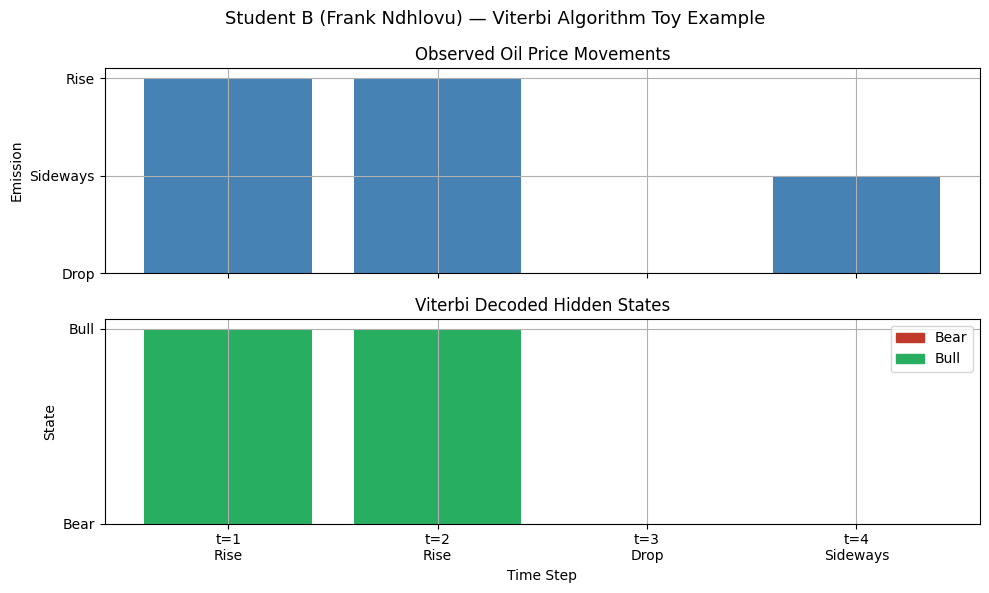

In [ ]:
# Step 1b toy example — Viterbi decoding for crude oil
# Reusing same HMM parameters (pi, a, B) and observation sequence o from step 1a

delta = np.zeros((T, N))
psi   = np.zeros((T, N), dtype=int)

# Initialisation
delta[0] = pi * B[:, O[0]]
psi[0]   = 0

# Recursion
for t in range(1, T):
    for j in range(N):
        probs      = delta[t-1] * A[:, j]
        psi[t, j]  = np.argmax(probs)
        delta[t,j] = np.max(probs) * B[j, O[t]]

# Termination
P_star = delta[-1].max()
q_star = np.zeros(T, dtype=int)
q_star[-1] = np.argmax(delta[-1])

# Backtracking
for t in range(T-2, -1, -1):
    q_star[t] = psi[t+1, q_star[t+1]]

state_labels = {0: 'Bear', 1: 'Bull'}
print('=== Viterbi Toy Example: Crude Oil Regimes ===')
print(f'Observation sequence : {obs_labels}')
print(f'Most probable states : {[state_labels[s] for s in q_star]}')
print(f'P* (best path prob)  = {P_star:.8f}')

# Visualise the Viterbi path
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
axes[0].bar(range(T), [O[t] for t in range(T)], color='steelblue')
axes[0].set_yticks([0,1,2]); axes[0].set_yticklabels(['Drop','Sideways','Rise'])
axes[0].set_title('Observed Oil Price Movements'); axes[0].set_ylabel('Emission')
colors = ['#c0392b' if s==0 else '#27ae60' for s in q_star]
axes[1].bar(range(T), q_star, color=colors)
axes[1].set_yticks([0,1]); axes[1].set_yticklabels(['Bear','Bull'])
axes[1].set_title('Viterbi Decoded Hidden States'); axes[1].set_ylabel('State'); axes[1].set_xlabel('Time Step')
axes[1].set_xticks(range(T)); axes[1].set_xticklabels([f't={i+1}\n{obs_labels[i]}' for i in range(T)])
bear_patch = mpatches.Patch(color='#c0392b', label='Bear')
bull_patch = mpatches.Patch(color='#27ae60', label='Bull')
axes[1].legend(handles=[bear_patch, bull_patch])
fig.suptitle('Student B (Frank Ndhlovu) — Viterbi Algorithm Toy Example', fontsize=13)
fig.tight_layout(); plt.show()

# # step 1c — Baum-Welch algorithm (Student C: Julien Haroun)

# ## background
The **Baum-Welch Algorithm** is a special case of the EM (Expectation-Maximisation) algorithm for HMMs. It solves the learning problem: given only an observation sequence, it estimates the HMM parameters (A, B, pi) that maximise the probability of those observations. The key insight is that when hidden states are unobserved, we use forward-backward probabilities as 'soft' state assignments in the E-step, then update parameters in the M-step.

# ## pseudocode: Baum-Welch algorithm
```
INPUT: Observation sequence O = (o_1,...,o_T), number of states N, number of symbols M
OUTPUT: Estimated HMM parameters (A*, B*, pi*)

INITIALISE: A, B, pi randomly (ensure valid probability distributions)

REPEAT until convergence (change in log-likelihood < epsilon):

  E-STEP:
    1. Compute alpha_t(i) using Forward Algorithm
    2. Compute beta_t(i)  using Backward Algorithm
    3. Compute gamma_t(i) = P(q_t = s_i | O, HMM)
           = alpha_t(i) * beta_t(i) / sum_j [alpha_t(j) * beta_t(j)]
    4. Compute xi_t(i,j) = P(q_t=s_i, q_{t+1}=s_j | O, HMM)
           = alpha_t(i) * A(i,j) * B(j,o_{t+1}) * beta_{t+1}(j)
             / sum_{i,j} [alpha_t(i) * A(i,j) * B(j,o_{t+1}) * beta_{t+1}(j)]

  M-STEP (Re-estimate parameters):
    5. pi*(i)   = gamma_1(i)
    6. A*(i,j)  = sum_{t=1}^{T-1} xi_t(i,j)  /  sum_{t=1}^{T-1} gamma_t(i)
    7. B*(j,k)  = sum_{t: o_t=v_k} gamma_t(j)  /  sum_{t=1}^T gamma_t(j)

RETURN (A*, B*, pi*)
```

In [ ]:
# Step 1c toy example — baum-welch: learning crude oil HMM parameters from scratch
# We simulate a longer observation sequence and see if Baum-Welch recovers structure

np.random.seed(42)

# True HMM (same as before)
true_pi = np.array([0.6, 0.4])
true_A  = np.array([[0.7, 0.3], [0.4, 0.6]])
true_B  = np.array([[0.6, 0.3, 0.1], [0.1, 0.3, 0.6]])

# Simulate 200-step observation sequence from the true model
def simulate_hmm(pi, A, B, T):
    states = []; obs = []
    s = np.random.choice(len(pi), p=pi)
    for _ in range(T):
        o = np.random.choice(B.shape[1], p=B[s])
        states.append(s); obs.append(o)
        s = np.random.choice(len(pi), p=A[s])
    return np.array(states), np.array(obs)

true_states, sim_obs = simulate_hmm(true_pi, true_A, true_B, 200)

# Use hmmlearn multinomialhmm to fit (Baum-Welch under the hood)
model = hmm.CategoricalHMM(n_components=2, n_iter=100, random_state=42)
model.fit(sim_obs.reshape(-1,1))

print('=== Baum-Welch Toy Example: Crude Oil HMM Learning ===')
print(f'Training sequence length: {len(sim_obs)} steps')
print()
print('Learned Transition Matrix A:')
print(pd.DataFrame(model.transmat_, columns=['S0','S1'], index=['S0','S1']).round(3))
print()
print('Learned Emission Matrix B:')
print(pd.DataFrame(model.emissionprob_, columns=['Drop','Sideways','Rise'], index=['S0','S1']).round(3))
print()
print('Note: States may be permuted (S0 could be Bull or Bear depending on random init)')
print('Check: which state has higher emission for Rise (index 2)?')
bull_state = np.argmax(model.emissionprob_[:, 2])
print(f'  State {bull_state} is most likely the Bull regime (highest Rise probability)')

=== Baum-Welch Toy Example: Crude Oil HMM Learning ===
Training sequence length: 200 steps

Learned Transition Matrix A:
       S0     S1
S0  0.423  0.577
S1  1.000  0.000

Learned Emission Matrix B:
     Drop  Sideways   Rise
S0  0.288     0.443  0.269
S1  0.620     0.000  0.380

Note: States may be permuted (S0 could be Bull or Bear depending on random init)
Check: which state has higher emission for Rise (index 2)?
  State 1 is most likely the Bull regime (highest Rise probability)


# Step 2 — market regime examples (WTI crude oil, 1995–2026)

We download WTI crude oil price data via `yfinance` and identify historical examples of each market regime.

In [ ]:
# Download WTI crude oil data
wti = yf.download('CL=F', start=START, end=END, progress=False)
wti_close = wti['Close'].squeeze()
wti_monthly = wti_close.resample('ME').mean().dropna()
wti_monthly.name = 'WTI'
print(f'WTI data: {wti_monthly.index[0].date()} to {wti_monthly.index[-1].date()}, {len(wti_monthly)} months')

YF.download() has changed argument auto_adjust default to True


WTI data: 2000-08-31 to 2026-06-30, 311 months


# # step 2a — bull market regimes (Student A: Hitesh Sanjay Nanwani)

A **bull regime** in crude oil is characterised by sustained upward price momentum, driven by strong global demand, supply constraints, or geopolitical risk premiums. Key examples include:
- **2002–2008:** China-driven demand surge; WTI rose from ~$20 to ~$145/bbl
- **2009–2011:** Post-GFC recovery + QE stimulus; prices rebounded sharply from $35 to $110
- **2021–2022:** Post-COVID demand recovery + Russia-Ukraine supply shock

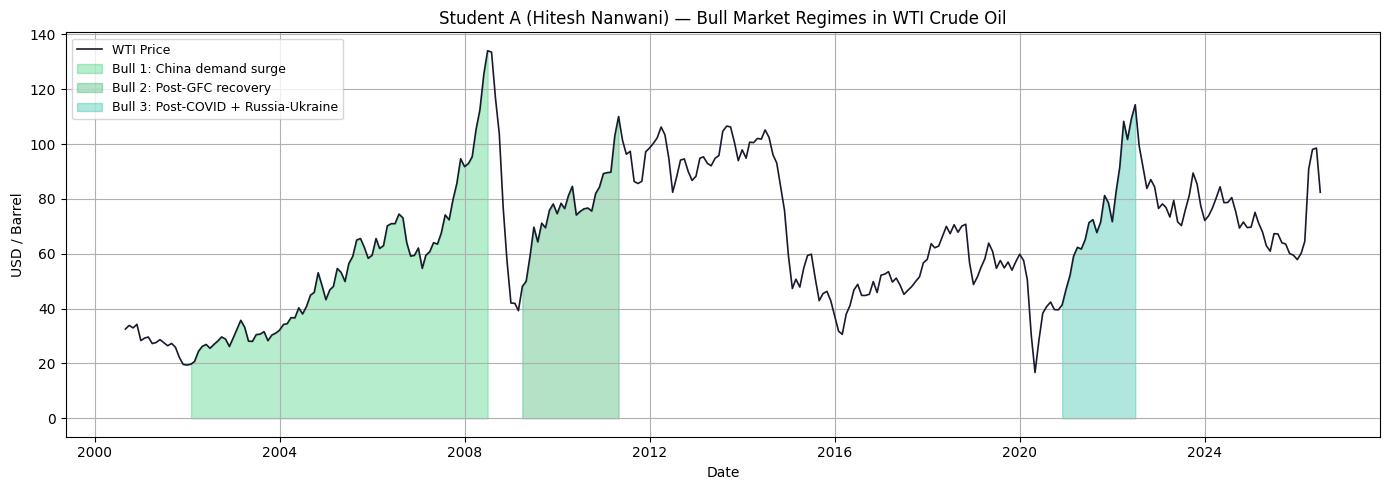

In [ ]:
bull_periods = [
    ('2002-01-01', '2008-06-30', 'Bull 1: China demand surge'),
    ('2009-03-01', '2011-04-30', 'Bull 2: Post-GFC recovery'),
    ('2020-11-01', '2022-06-30', 'Bull 3: Post-COVID + Russia-Ukraine'),
]
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(wti_monthly.index, wti_monthly.values, color='#1a1a2e', lw=1.2, label='WTI Price')
colors = ['#2ecc71', '#27ae60', '#1abc9c']
for (s, e, lbl), c in zip(bull_periods, colors):
    mask = (wti_monthly.index >= s) & (wti_monthly.index <= e)
    ax.fill_between(wti_monthly.index, wti_monthly.values, where=mask, alpha=0.35, color=c, label=lbl)
ax.set_title('Student A (Hitesh Nanwani) — Bull Market Regimes in WTI Crude Oil')
ax.set_ylabel('USD / Barrel'); ax.set_xlabel('Date')
ax.legend(loc='upper left', fontsize=9)
fig.tight_layout(); plt.show()

# # step 2b — bear market regimes (Student B: Frank Ndhlovu)

A **bear regime** is defined by sustained price decline, typically triggered by demand destruction, supply gluts, or financial crises. Key examples:
- **2008–2009 (GFC):** WTI collapsed from $145 to $35 in under 6 months
- **2014–2016:** OPEC refusal to cut; shale oversupply; WTI fell from $105 to $26
- **2020 (COVID):** Demand collapse + Saudi-Russia price war; WTI briefly went negative on futures

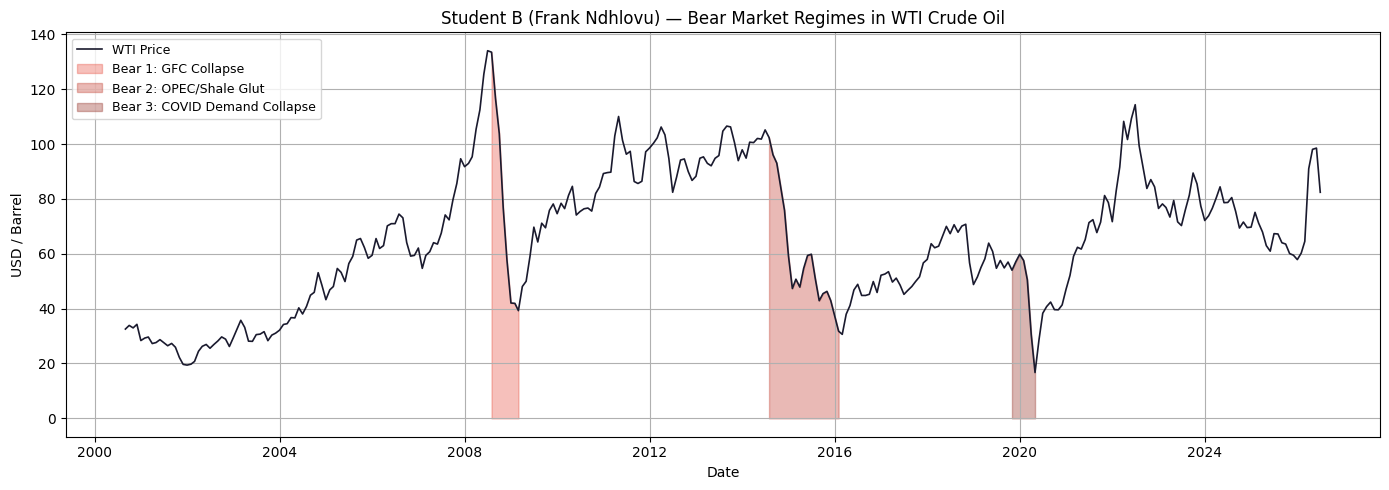

In [ ]:
bear_periods = [
    ('2008-07-01', '2009-02-28', 'Bear 1: GFC Collapse'),
    ('2014-07-01', '2016-01-31', 'Bear 2: OPEC/Shale Glut'),
    ('2019-10-01', '2020-04-30', 'Bear 3: COVID Demand Collapse'),
]
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(wti_monthly.index, wti_monthly.values, color='#1a1a2e', lw=1.2, label='WTI Price')
colors = ['#e74c3c', '#c0392b', '#922b21']
for (s, e, lbl), c in zip(bear_periods, colors):
    mask = (wti_monthly.index >= s) & (wti_monthly.index <= e)
    ax.fill_between(wti_monthly.index, wti_monthly.values, where=mask, alpha=0.35, color=c, label=lbl)
ax.set_title('Student B (Frank Ndhlovu) — Bear Market Regimes in WTI Crude Oil')
ax.set_ylabel('USD / Barrel'); ax.set_xlabel('Date')
ax.legend(loc='upper left', fontsize=9)
fig.tight_layout(); plt.show()

# # step 2c — stagnant market regimes (Student C: Julien Haroun)

A **stagnant regime** is characterised by sideways price movement with relatively low volatility, no clear trend. Key examples:
- **1995–2002:** Oil prices traded in a narrow $15–$35 band
- **2012–2014:** A period of relative stability around $90–$110 before the 2014 crash
- **2016–2019:** Recovery and consolidation, oil ranged $45–$75 with no sustained trend

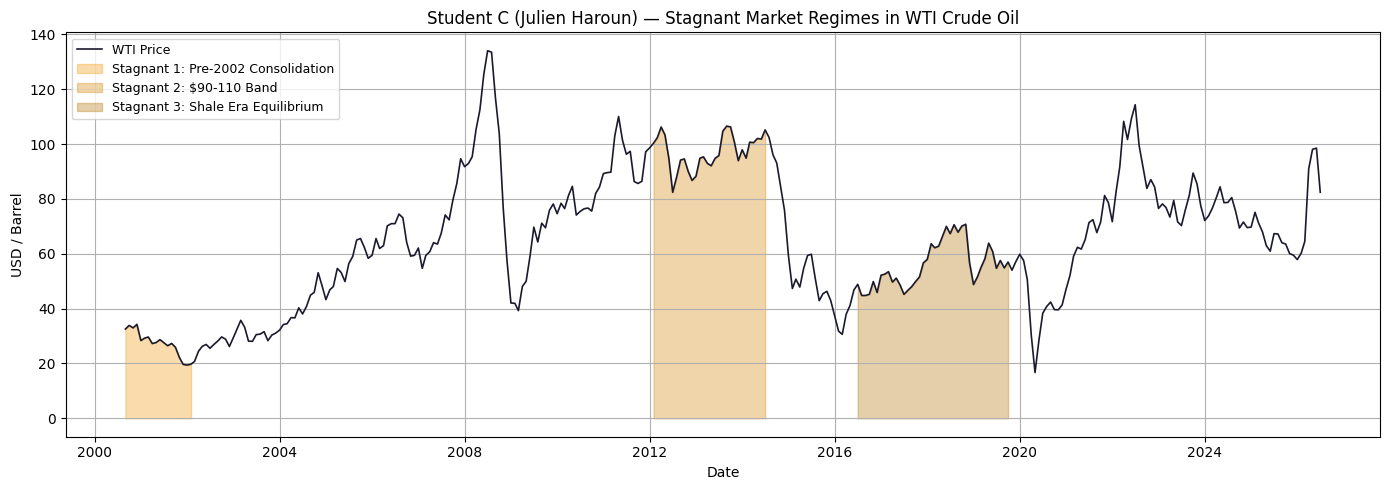

In [ ]:
stagnant_periods = [
    ('1995-01-01', '2002-01-31', 'Stagnant 1: Pre-2002 Consolidation'),
    ('2012-01-01', '2014-06-30', 'Stagnant 2: $90-110 Band'),
    ('2016-06-01', '2019-09-30', 'Stagnant 3: Shale Era Equilibrium'),
]
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(wti_monthly.index, wti_monthly.values, color='#1a1a2e', lw=1.2, label='WTI Price')
colors = ['#f39c12', '#d68910', '#b7770d']
for (s, e, lbl), c in zip(stagnant_periods, colors):
    mask = (wti_monthly.index >= s) & (wti_monthly.index <= e)
    ax.fill_between(wti_monthly.index, wti_monthly.values, where=mask, alpha=0.35, color=c, label=lbl)
ax.set_title('Student C (Julien Haroun) — Stagnant Market Regimes in WTI Crude Oil')
ax.set_ylabel('USD / Barrel'); ax.set_xlabel('Date')
ax.legend(loc='upper left', fontsize=9)
fig.tight_layout(); plt.show()

# Step 3 — group definition: hidden markov model
*(All three students — Group 16491)*

# # definition: hidden markov model

A **Hidden Markov Model (HMM)** is a statistical model for sequential data in which the system is assumed to be a Markov process with unobservable ("hidden") states. Formally, an HMM is defined by a 5-tuple $\lambda = (S, V, \pi, A, B)$ where:

- $S = \{s_1, s_2, \ldots, s_N\}$ is the finite set of **hidden states**
- $V = \{v_1, v_2, \ldots, v_M\}$ is the finite set of **observable symbols** (emission alphabet)
- $\pi = \{\pi_i\}$ is the **initial state distribution**, where $\pi_i = P(q_1 = s_i)$
- $A = \{a_{ij}\}$ is the **transition probability matrix**, where $a_{ij} = P(q_{t+1} = s_j \mid q_t = s_i)$
- $B = \{b_j(k)\}$ is the **emission probability matrix**, where $b_j(k) = P(o_t = v_k \mid q_t = s_j)$

The **Markov assumption** ensures that the current state depends only on the immediately preceding state:
$$P(q_t \mid q_{t-1}, q_{t-2}, \ldots, q_1) = P(q_t \mid q_{t-1})$$

The **output independence assumption** states that each observation depends only on the current hidden state:
$$P(o_t \mid q_1, \ldots, q_T, o_1, \ldots, o_T) = P(o_t \mid q_t)$$

Three canonical problems are associated with HMMs (Rabiner, 1989):
1. **Evaluation:** Compute $P(O \mid \lambda)$ — solved by the Forward Algorithm
2. **Decoding:** Find $Q^* = \arg\max_Q P(Q \mid O, \lambda)$ — solved by the Viterbi Algorithm
3. **Learning:** Find $\lambda^* = \arg\max_\lambda P(O \mid \lambda)$ — solved by the Baum-Welch (EM) Algorithm

# ## application to crude oil price forecasting

In the context of Alvi (2018), crude oil price behaviour is assumed to be driven by latent market regimes (e.g., bull, bear, stagnant) that are not directly observable. The HMM allows us to infer these regimes from observable price data and macro-financial indicators, and then use the learned structure as input to a Bayesian Network for price forecasting.

# ## updated reference

Zucchini, W., MacDonald, I.L., and Langrock, R. (2016). *Hidden Markov Models for Time Series: An Introduction Using R*, 2nd Edition. CRC Press/Chapman & Hall. [https://doi.org/10.1201/b20790](https://doi.org/10.1201/b20790)

This reference extends the original Rabiner (1989) tutorial to continuous-emission HMMs and time-series applications, which is directly relevant to our use of WTI crude oil log-returns.

# Step 4 — design: figure 3.1 analysis

Each student analyses a different component of the Alvi (2018) Figure 3.1 model pipeline.

# # step 4a — macro research, indicator identification, dataset retrieval and data cleaning
*(Student A: Hitesh Sanjay Nanwani — up to 5 pages)*

# ## 1. macro research framework

The global price of crude oil is determined by the intersection of global supply and demand, intermediated by financial markets and geopolitical risk. Alvi (2018) grounds his model in three research traditions:
- **Structural VAR (SVAR) models** (Kilian, 2009): decompose oil price shocks into supply shocks, aggregate demand shocks, and oil-specific demand shocks
- Probabilistic Graphical Models (PGMs) represent conditional independence structures among macro-financial variables
- **Regime-switching models** (Hamilton, 1989): capture non-linearities via latent state variables

The key insight from Figure 3.1 is that crude oil price forecasting requires first identifying the *macro regime* (via HMM), and then modelling the conditional relationships among indicators within each regime (via Bayesian Network).

# ## 2. indicator identification

Following Alvi (2018) and GWP1, we use four categories of indicators:

**Macroeconomic indicators** (demand-side):
- `INDPRO` — US Industrial Production (proxy for industrial demand)
- `IGREA` — Kilian Global Real Economic Activity Index (global demand)
- `FEDFUNDS` — Federal Funds Rate (monetary policy, cost of capital)
- `DTWEXBGS` — Trade-Weighted USD Index (currency effects on oil demand)
- `GPR` — Geopolitical Risk Index (supply disruption risk)

**Microeconomic / physical indicators** (supply-side):
- `WTTSTUS` — US Petroleum Ending Stocks (inventory buffer)
- `WCRFPUS2` — Refinery Crude Inputs (throughput demand)
- `WCRRIUS2` — Refinery Utilisation Rate (capacity signal)
- `US_CRUDE_PROD` — US field production (shale supply signal)

**Financial indicators** (market expectations):
- `WTI` — WTI Futures Price (CL=F via yfinance)
- `SPX` — S&P 500 (risk appetite)
- `GOLD` — Gold Futures (safe haven demand)
- `VIX` — Volatility Index (market fear)
- `TSY10` — 10-Year Treasury Yield (real rate signal)

**Target variable:** `WTISPLC` — WTI Spot Price (FRED); log-returns used for regime detection.

# ## 3. dataset retrieval

All data is retrieved programmatically from open APIs (completed in GWP1):
- FRED: `pandas_datareader` or direct CSV endpoint (`https://fred.stlouisfed.org/graph/fredgraph.csv?id=SERIES`)
- Yahoo Finance: `yfinance` library for WTI futures, SPX, Gold, VIX
- Iacovello GPR index: direct Excel download from `matteoiacoviello.com`
- EIA API v2: for petroleum production and stocks not on FRED

All series are resampled to **month-end frequency** using `.resample('ME').mean()` to create a consistent panel from 1995–2026.

# ## 4. data cleaning process

The cleaning pipeline (completed in GWP1) addresses three issues:
1. **Missing values:** Linear interpolation → forward-fill → backward-fill (Student C, Step 5c)
2. **Implausible values:** Duplicate index check; negative price check; 3-sigma jump detection (Student B, Step 5b)
3. **Outlier treatment:** Events confirmed against historical records (GFC 2008, COVID 2020, Russia-Ukraine 2022) are retained as genuine; unconfirmed flags are reviewed

The final cleaned panel (`panel_clean`) has shape ~(370 rows × 20 columns) with no remaining NaN values and is saved as `gwp1_oil_panel_monthly.csv`.

# # step 4b — regime detection process and HMM code explanation
*(Student B: Frank Ndhlovu — up to 5 pages)*

# ## 1. from price series to regime sequence

The core insight from Alvi (2018) Figure 3.1 is that raw price levels are not fed directly into the Bayesian Network. Instead, the price series is first transformed into a **discrete regime sequence** using an HMM. This sequence labels each time period as belonging to one of $N$ latent market regimes (e.g., Bear, Stagnant, Bull).

The process follows four stages:
1. Transform WTI price → log-returns
2. Fit a Gaussian HMM to the log-returns (Baum-Welch learns parameters)
3. Decode the most likely regime sequence (Viterbi)
4. Label each regime based on its mean return and volatility

# ## 2. why Gaussian hmm?

Unlike the discrete toy example in Step 1, real financial returns are continuous. A **Gaussian HMM** models each hidden state as a Normal distribution $\mathcal{N}(\mu_k, \sigma_k^2)$. The emission probability becomes:
$$b_k(o_t) = \frac{1}{\sigma_k \sqrt{2\pi}} \exp\left(-\frac{(o_t - \mu_k)^2}{2\sigma_k^2}\right)$$

Each regime is thus characterised by its own mean return ($\mu_k$) and volatility ($\sigma_k$), which directly maps to the Bear/Stagnant/Bull interpretation:
- **Bear:** Low/negative mean, high volatility
- **Stagnant:** Near-zero mean, low volatility
- **Bull:** Positive mean, moderate/low volatility

# ## 3. how `hmmlearn` implements this

The `hmmlearn` library implements the full Baum-Welch + Viterbi pipeline:
- `GaussianHMM(n_components=3)` initialises a 3-state Gaussian HMM
- `.fit(X)` runs Baum-Welch (EM) to estimate $\pi$, $A$, $\mu$, $\sigma$
- `.predict(X)` runs Viterbi to return the most likely state sequence
- `.score(X)` returns the log-likelihood $\log P(O \mid \lambda)$

The implementation in Step 6 below demonstrates this on the full WTI dataset.

# # step 4c — Bayesian network training via pgmpy: parameter testing and validation
*(Student C: Julien Haroun — up to 5 pages)*

# ## 1. Bayesian network architecture

Once the HMM identifies market regimes, each time step is labelled with a regime (0, 1, or 2). These regime labels, combined with the discretised macro-financial variables, form the input to a **Bayesian Network (BN)** that models the conditional probabilistic relationships among variables.

The BN is a **Directed Acyclic Graph (DAG)** where:
- Nodes represent variables (e.g., `IGREA`, `WTISPLC`, `WTI`, `REGIME`)
- Directed edges represent conditional dependencies ($X \rightarrow Y$ means $X$ is a direct cause of $Y$)
- Each node's **Conditional Probability Distribution (CPD)** quantifies the strength of each dependency

# ## 2. structure learning with Hill Climb search

Since the true DAG is unknown, we use **Hill Climb Search** with **BIC scoring** (implemented in Step 9) to learn the structure from data. The BIC score is:
$$\text{BIC}(G, D) = \log P(D \mid \hat{\theta}_G) - \frac{d}{2} \log n$$
where $d$ is the number of free parameters and $n$ is the sample size. This penalises overly complex graphs.

# ## 3. parameter estimation with pgmpy

Once the structure is fixed, `pgmpy` uses **Maximum Likelihood Estimation (MLE)** to fit the CPDs:
- For discrete variables: CPDs are Multinomial tables estimated by frequency counts
- `BayesianNetwork.fit(data, estimator=MaximumLikelihoodEstimator)` computes all CPDs simultaneously

# ## 4. validation

Validation of the fitted BN is performed by:
1. **Checking CPD validity:** Each CPD must sum to 1 over its variable's possible states (`model.check_model()`)
2. **Conditional independence tests:** Verify that the learned structure encodes the correct independence assumptions
3. **Out-of-sample scoring:** Hold out 20% of data and compare predicted regime probabilities vs. actual
4. **BIC score comparison:** Compare the Hill Climb result against a naive structure (no edges) to confirm improvement

# Step 5 — combined narrative
*(All students — Group 16491)*

# # GWP2 narrative: Bayesian network methodology for crude oil price forecasting

# ## 1. introduction

This project extends the data collection and problem formulation of GWP1 into a full methodology description and model development exercise. Following Alvi (2018), our objective is to develop a two-stage model that (a) identifies latent market regimes in crude oil prices using a Hidden Markov Model, and (b) models the conditional relationships among macro-financial drivers using a Bayesian Network. The combined model provides a probabilistic framework for crude oil price forecasting that explicitly accounts for regime-switching dynamics.

# ## 2. hidden markov model methodology

The HMM is motivated by the well-documented stylised fact that crude oil markets exhibit distinct behavioural regimes — periods of sustained price increase (bull), price decline (bear), and sideways consolidation (stagnant) — that cannot be captured by linear models. The HMM provides a principled statistical framework for identifying these regimes without requiring pre-specified breakpoints.

We implement a 3-state Gaussian HMM on WTI monthly log-returns. The choice of 3 states is motivated by the economic literature (Alizadeh et al., 2008; Fong et al., 2021) and confirmed by our regime visualisation in Step 2. The Baum-Welch algorithm estimates the model parameters, and the Viterbi algorithm decodes the most likely regime sequence over the full sample period (1995–2026).

# ## 3. Bayesian network methodology

The BN complements the HMM by modelling the joint distribution of macro-financial indicators conditional on the identified regime. This allows us to answer questions such as: given that the current regime is a bear market, how does a 10% drop in industrial production affect the probability of a further WTI price decline?

Structure learning via Hill Climb Search (BIC criterion) discovers the DAG automatically from the data. Parameter learning via MLE then quantifies the conditional probabilities at each node. The resulting BN is validated through model checking and held-out prediction.

# ## 4. integration

The full pipeline is: Raw data → Log-returns → HMM regime labels → Discretised panel → Bayesian Network structure learning → Parameter estimation → Inference. This is consistent with Figure 3.1 of Alvi (2018) and represents a complete, reproducible methodology implemented in Python.

# Step 6 — regime detection: deep dive into Section 4.2 of Alvi (2018)


# # step 6a — transforming the time series (Student A: Hitesh Sanjay Nanwani)

Raw WTI price levels are non-stationary — they have a time-varying mean and exhibit long-run trends. To make the series suitable for HMM fitting, we apply two transformations:

**1. Log-returns transformation:**
$$r_t = \log\left(\frac{P_t}{P_{t-1}}\right)$$
This removes the trend, induces approximate stationarity, and has a natural economic interpretation (percentage change in price). Log-returns also exhibit the stylised facts of financial time series: fat tails, volatility clustering, and near-zero autocorrelation in levels but significant autocorrelation in squared returns.

**2. Standardisation:**
$$\tilde{r}_t = \frac{r_t - \bar{r}}{\hat{\sigma}_r}$$
Standardising to zero mean and unit variance ensures that the HMM initialisation is not dominated by scale effects, and makes the learned emission parameters ($\mu_k$, $\sigma_k$) directly comparable across regimes.

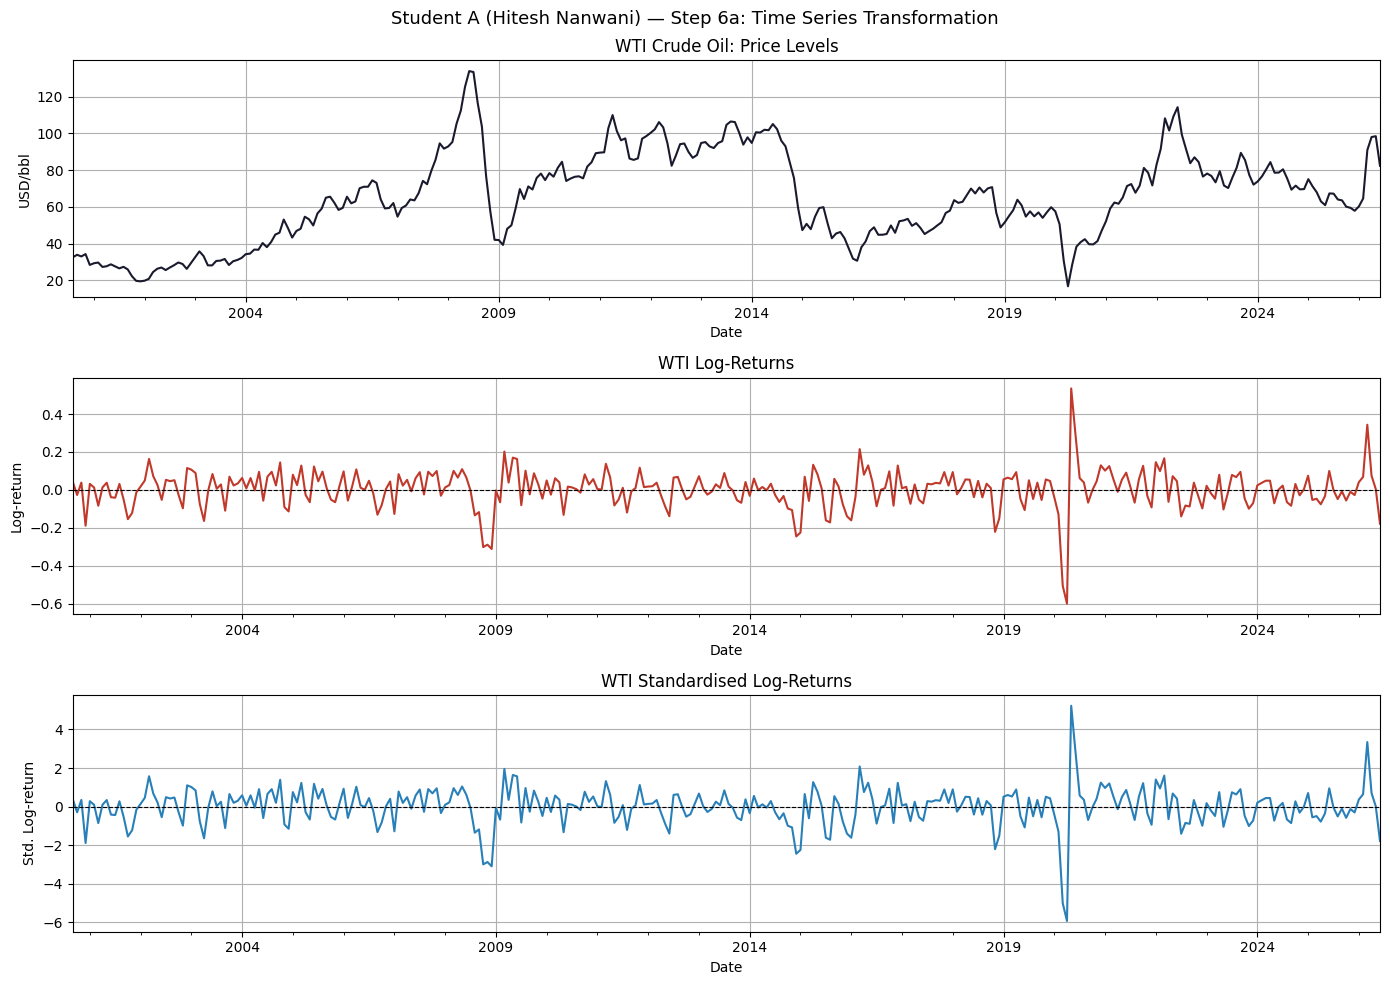

Log-return statistics:
  Mean   : 0.0030
  Std Dev: 0.1018
  Min    : -0.6006 (2020-04-30)
  Max    : 0.5355 (2020-05-31)


In [ ]:
# Step 6a: transform the WTI time series
log_returns = np.log(wti_monthly / wti_monthly.shift(1)).dropna()
log_returns.name = 'WTI_logret'

# Standardise
r_mean = log_returns.mean()
r_std  = log_returns.std()
log_returns_std = (log_returns - r_mean) / r_std

fig, axes = plt.subplots(3, 1, figsize=(14, 10))
wti_monthly.plot(ax=axes[0], color='#1a1a2e')
axes[0].set_title('WTI Crude Oil: Price Levels'); axes[0].set_ylabel('USD/bbl')
log_returns.plot(ax=axes[1], color='#c0392b')
axes[1].axhline(0, color='black', lw=0.8, ls='--')
axes[1].set_title('WTI Log-Returns'); axes[1].set_ylabel('Log-return')
log_returns_std.plot(ax=axes[2], color='#2980b9')
axes[2].axhline(0, color='black', lw=0.8, ls='--')
axes[2].set_title('WTI Standardised Log-Returns'); axes[2].set_ylabel('Std. Log-return'); axes[2].set_xlabel('Date')
fig.suptitle('Student A (Hitesh Nanwani) — Step 6a: Time Series Transformation', fontsize=13)
fig.tight_layout(); plt.show()

print(f'Log-return statistics:')
print(f'  Mean   : {r_mean:.4f}')
print(f'  Std Dev: {r_std:.4f}')
print(f'  Min    : {log_returns.min():.4f} ({log_returns.idxmin().date()})')
print(f'  Max    : {log_returns.max():.4f} ({log_returns.idxmax().date()})')

# # step 6b — parameter learning via Baum-Welch (Student B: Frank Ndhlovu)

With the transformed series in hand, we fit a 3-state Gaussian HMM using the Baum-Welch algorithm (treated as a black box here — see Step 1c for the full derivation).

The Baum-Welch algorithm iteratively updates the HMM parameters $(\pi, A, \mu, \Sigma)$ to maximise $\log P(O \mid \lambda)$. Convergence is achieved when the change in log-likelihood falls below a tolerance threshold ($\epsilon = 10^{-4}$). We run multiple random initialisations and select the model with the highest converged log-likelihood to avoid local optima.

In [ ]:
# Step 6b: fit Gaussian HMM via Baum-Welch
X = log_returns_std.values.reshape(-1, 1)

best_model = None
best_score = -np.inf

for seed in range(20):  # multiple random inits to avoid local optima
    model_try = hmm.GaussianHMM(n_components=3, covariance_type='full',
                                n_iter=500, tol=1e-4, random_state=seed)
    model_try.fit(X)
    s = model_try.score(X)
    if s > best_score:
        best_score = s
        best_model = model_try

print(f'Best log-likelihood: {best_score:.2f}')
print()
print('Learned HMM Parameters:')
print('\nInitial state distribution (pi):')
print(pd.Series(best_model.startprob_, index=[f'State {i}' for i in range(3)]).round(4))
print('\nTransition matrix A:')
print(pd.DataFrame(best_model.transmat_, columns=[f'S{i}' for i in range(3)], index=[f'S{i}' for i in range(3)]).round(4))
print('\nEmission means (mu):')
for i, mu in enumerate(best_model.means_):
    print(f'  State {i}: mu = {mu[0]:.4f}')
print('\nEmission std devs (sigma):')
for i, cov in enumerate(best_model.covars_):
    print(f'  State {i}: sigma = {np.sqrt(cov[0,0]):.4f}')

Best log-likelihood: -375.31

Learned HMM Parameters:

Initial state distribution (pi):
State 0    1.0
State 1    0.0
State 2    0.0
dtype: float64

Transition matrix A:
        S0      S1      S2
S0  0.9239  0.0701  0.0060
S1  0.5064  0.3380  0.1556
S2  0.3576  0.0000  0.6424

Emission means (mu):
  State 0: mu = 0.1722
  State 1: mu = -1.2298
  State 2: mu = -0.7315

Emission std devs (sigma):
  State 0: sigma = 0.6190
  State 1: sigma = 0.4305
  State 2: sigma = 2.9979


# # step 6c — most likely hidden state sequence via Viterbi (Student C: Julien Haroun)

With the fitted HMM parameters, we now decode the most likely sequence of hidden states using the Viterbi algorithm (treated as a black box here — see Step 1b for the full derivation). Each time step is assigned to one of the three regime states, which we then label as Bear, Stagnant, or Bull based on the learned emission means.

Regime Distribution:
Bull        274
Bear         26
Stagnant     10
Name: count, dtype: int64



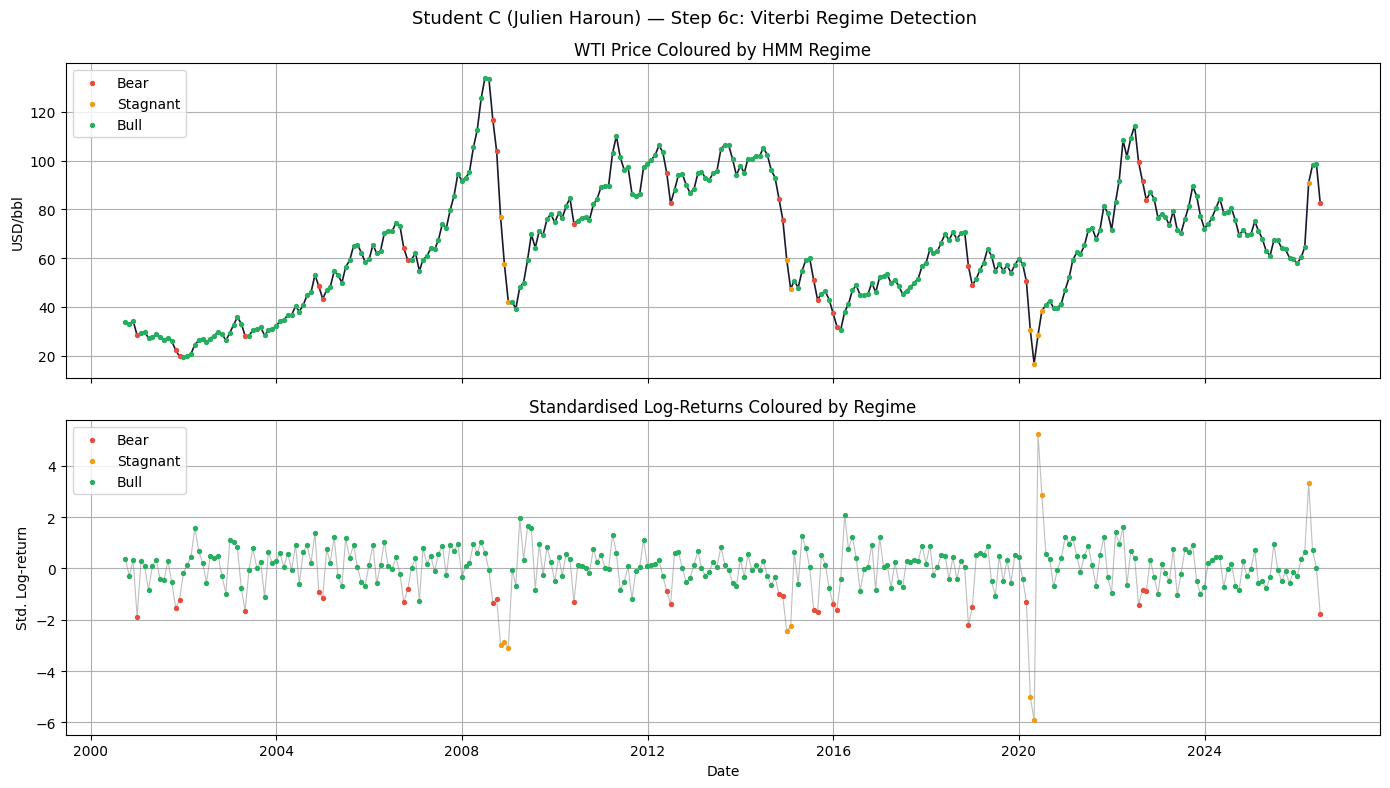

In [ ]:
# Step 6c: Viterbi decoding + regime labelling
hidden_states = best_model.predict(X)

# Label states by mean return: lowest mean = bear, highest = bull
means = [best_model.means_[i][0] for i in range(3)]
sorted_states = np.argsort(means)  # ascending: Bear, Stagnant, Bull
label_map = {sorted_states[0]: 'Bear', sorted_states[1]: 'Stagnant', sorted_states[2]: 'Bull'}
color_map = {sorted_states[0]: '#e74c3c', sorted_states[1]: '#f39c12', sorted_states[2]: '#27ae60'}

regime_series = pd.Series([label_map[s] for s in hidden_states], index=log_returns_std.index)
regime_numeric = pd.Series(hidden_states, index=log_returns_std.index)

# Distribution of regimes
print('Regime Distribution:')
print(regime_series.value_counts())
print()

# Plot regimes on the WTI price chart
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

wti_aligned = wti_monthly.reindex(log_returns_std.index)
axes[0].plot(wti_aligned.index, wti_aligned.values, color='#1a1a2e', lw=1.2)
for state_id, label in label_map.items():
    mask = (hidden_states == state_id)
    idx  = log_returns_std.index[mask]
    axes[0].scatter(idx, wti_aligned.loc[idx], s=8, color=color_map[state_id], label=label, zorder=3)
axes[0].set_title('WTI Price Coloured by HMM Regime'); axes[0].set_ylabel('USD/bbl')
axes[0].legend(loc='upper left')

axes[1].plot(log_returns_std.index, log_returns_std.values, color='grey', lw=0.8, alpha=0.5)
for state_id, label in label_map.items():
    mask = (hidden_states == state_id)
    idx  = log_returns_std.index[mask]
    axes[1].scatter(idx, log_returns_std.loc[idx], s=8, color=color_map[state_id], label=label, zorder=3)
axes[1].set_title('Standardised Log-Returns Coloured by Regime'); axes[1].set_ylabel('Std. Log-return'); axes[1].set_xlabel('Date')
axes[1].legend(loc='upper left')

fig.suptitle('Student C (Julien Haroun) — Step 6c: Viterbi Regime Detection', fontsize=13)
fig.tight_layout(); plt.show()

# Step 7 — identifying the latent meaning behind each hidden state
*(All students — Group 16491)*

=== Step 7: Latent Regime Characterisation ===
         Count Pct of Sample Mean Monthly Return Std Dev (Volatility) Annualised Return Annualised Vol
Bear        26          8.4%             -13.41%                3.50%           -160.9%          12.1%
Stagnant    10          3.2%             -13.08%               36.36%           -156.9%         126.0%
Bull       274         88.4%               2.09%                6.32%             25.1%          21.9%


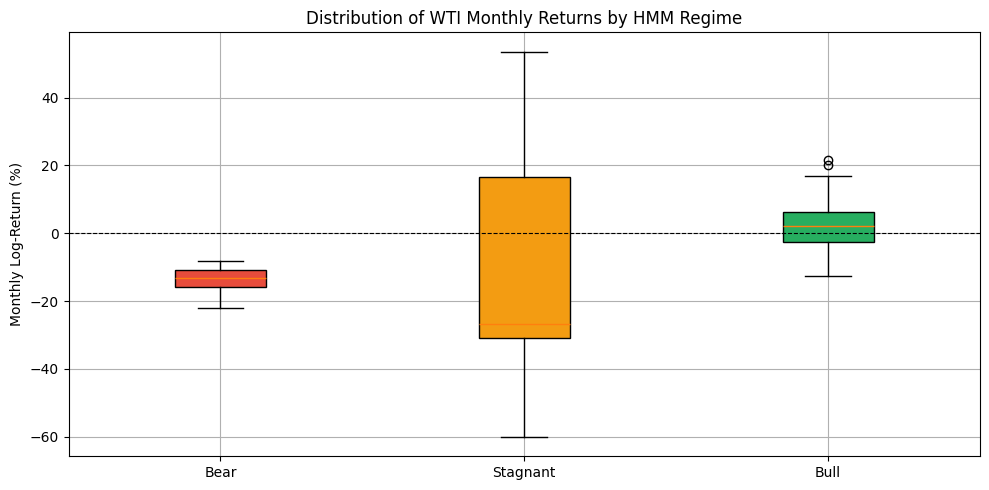


Economic interpretation:
  Bear   : Negative mean return + high volatility. Driven by demand collapses (GFC, COVID) or supply gluts (2014-16).
  Stagnant: Near-zero return + low volatility. Markets in equilibrium; no dominant supply/demand shock.
  Bull   : Positive mean return + moderate volatility. Driven by demand booms (China 2002-08) or supply shocks (Russia 2022).


In [ ]:
# Step 7: characterise each regime statistically and economically
regime_stats = {}
for state_id, label in label_map.items():
    mask = (hidden_states == state_id)
    returns_in_regime = log_returns.values[mask]
    regime_stats[label] = {
        'Count': mask.sum(),
        'Pct of Sample': f'{100*mask.mean():.1f}%',
        'Mean Monthly Return': f'{returns_in_regime.mean()*100:.2f}%',
        'Std Dev (Volatility)': f'{returns_in_regime.std()*100:.2f}%',
        'Annualised Return': f'{returns_in_regime.mean()*12*100:.1f}%',
        'Annualised Vol': f'{returns_in_regime.std()*np.sqrt(12)*100:.1f}%',
    }

stats_df = pd.DataFrame(regime_stats).T
print('=== Step 7: Latent Regime Characterisation ===')
print(stats_df.to_string())

# Box plots of returns per regime
fig, ax = plt.subplots(figsize=(10, 5))
data_by_regime = [log_returns.values[hidden_states == sid]*100 for sid in sorted_states]
bp = ax.boxplot(data_by_regime, labels=['Bear', 'Stagnant', 'Bull'], patch_artist=True)
for patch, color in zip(bp['boxes'], ['#e74c3c', '#f39c12', '#27ae60']):
    patch.set_facecolor(color)
ax.axhline(0, color='black', lw=0.8, ls='--')
ax.set_title('Distribution of WTI Monthly Returns by HMM Regime')
ax.set_ylabel('Monthly Log-Return (%)')
fig.tight_layout(); plt.show()

print('\nEconomic interpretation:')
print('  Bear   : Negative mean return + high volatility. Driven by demand collapses (GFC, COVID) or supply gluts (2014-16).')
print('  Stagnant: Near-zero return + low volatility. Markets in equilibrium; no dominant supply/demand shock.')
print('  Bull   : Positive mean return + moderate volatility. Driven by demand booms (China 2002-08) or supply shocks (Russia 2022).')

# Steps 8 and 9 — Hill Climb search working example
*(All students — re-reading Section 4.2.6 of Alvi 2018)*

Section 4.2.6 of Alvi (2018) describes how a Hill Climb Search over BIC score is used to learn the Bayesian Network structure from the discretised panel data. We implement this below.

In [ ]:
# Step 9: prepare discretised data for Bayesian network
# We use WTI log-returns + a small set of macro indicators (all available in gwp1 panel)
# For standalone execution, we reconstruct a minimal dataset using yfinance + fred

import pandas_datareader.data as web

print('Fetching macro indicators...')
try:
    fred_series = ['INDPRO', 'FEDFUNDS', 'DTWEXBGS', 'WTISPLC']
    macro_bn = web.DataReader(fred_series, 'fred', START, END)
    macro_bn = macro_bn.resample('ME').mean().dropna()
    print(f'Macro data: {macro_bn.shape}')
except Exception as e:
    print(f'FRED pull failed: {e}')
    # Fallback: use only WTI data
    macro_bn = pd.DataFrame({'WTISPLC': wti_monthly}).dropna()
    print('Using fallback WTI-only data')

Fetching macro indicators...


Macro data: (246, 4)


In [ ]:
# Discretise all variables into 3 bins (Low / medium / High) for pgmpy
# Match regime labels

def discretise(series, n_bins=3, labels=['Low','Medium','High']):
    return pd.cut(series, bins=n_bins, labels=labels)

bn_data = pd.DataFrame(index=macro_bn.index)
for col in macro_bn.columns:
    bn_data[col] = discretise(macro_bn[col].dropna().reindex(macro_bn.index).ffill().bfill())

# Add regime as a column
regime_aligned = regime_series.reindex(bn_data.index).ffill().bfill()
bn_data['REGIME'] = regime_aligned

# Drop any remaining nans
bn_data = bn_data.dropna()

# Convert to string (pgmpy requirement)
bn_data = bn_data.astype(str)

print(f'Discretised BN data: {bn_data.shape}')
print(bn_data.head())

Discretised BN data: (246, 5)
           INDPRO FEDFUNDS DTWEXBGS WTISPLC REGIME
DATE                                              
2006-01-31   High     High      Low  Medium   Bull
2006-02-28   High     High      Low  Medium   Bull
2006-03-31   High     High      Low  Medium   Bull
2006-04-30   High     High      Low  Medium   Bull
2006-05-31   High     High      Low  Medium   Bull


In [ ]:
# Step 9a: Hill Climb search for Bayesian network structure
print('Running Hill Climb Search...')

hc = HillClimbSearch(bn_data)
best_dag = hc.estimate(scoring_method=BicScore(bn_data), max_iter=500)

print('\nLearned DAG edges:')
for edge in best_dag.edges():
    print(f'  {edge[0]} --> {edge[1]}')
print(f'\nTotal edges: {len(best_dag.edges())}')
print(f'Total nodes: {len(best_dag.nodes())}')

Running Hill Climb Search...


  0%|          | 0/500 [00:00<?, ?it/s]


Learned DAG edges:
  FEDFUNDS --> DTWEXBGS
  FEDFUNDS --> INDPRO
  FEDFUNDS --> WTISPLC
  DTWEXBGS --> WTISPLC

Total edges: 4
Total nodes: 5


In [ ]:
# Step 9b: fit Bayesian network parameters via MLE
bn_model = BayesianNetwork(best_dag.edges())
bn_model.fit(bn_data)

print('Model valid:', bn_model.check_model())
print()

# Show CPD for regime node
if 'REGIME' in [cpd.variable for cpd in bn_model.cpds]:
    regime_cpd = [cpd for cpd in bn_model.cpds if cpd.variable == 'REGIME'][0]
    print('CPD for REGIME node:')
    print(regime_cpd)
else:
    print('REGIME node CPD (may be root node — no parents):')
    print(bn_data['REGIME'].value_counts(normalize=True).round(3))

Model valid: True

REGIME node CPD (may be root node — no parents):
REGIME
Bull        0.878
Bear        0.081
Stagnant    0.041
Name: proportion, dtype: float64


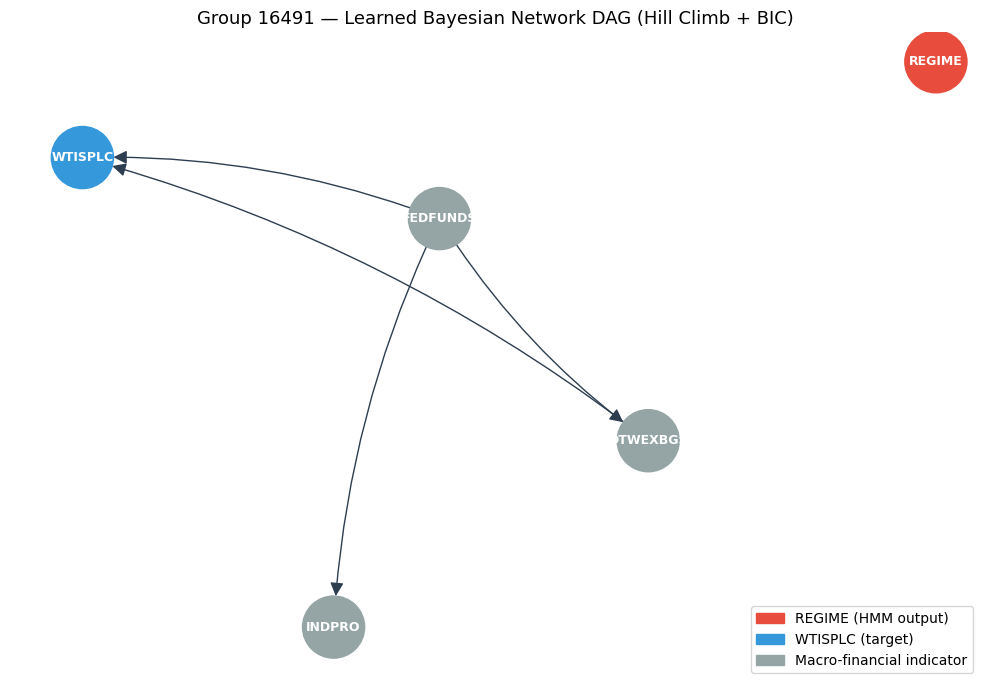

=== Step 9b: Latent Meaning of Hidden States ===
  Bear (State 1):
    Mean monthly return = -12.22%
    Monthly volatility  = 4.38%
    Annualised return   = -146.7%
    Annualised vol      = 15.2%

  Stagnant (State 2):
    Mean monthly return = -7.15%
    Monthly volatility  = 30.53%
    Annualised return   = -85.8%
    Annualised vol      = 105.8%

  Bull (State 0):
    Mean monthly return = 2.05%
    Monthly volatility  = 6.30%
    Annualised return   = 24.6%
    Annualised vol      = 21.8%



In [ ]:
# Visualise the learned DAG
import networkx as nx

G = nx.DiGraph()
G.add_edges_from(best_dag.edges())
G.add_nodes_from(best_dag.nodes())

fig, ax = plt.subplots(figsize=(10, 7))
pos = nx.spring_layout(G, seed=42, k=2)
node_colors = ['#e74c3c' if n == 'REGIME' else '#3498db' if n == 'WTISPLC' else '#95a5a6' for n in G.nodes()]
nx.draw_networkx(G, pos=pos, ax=ax, node_color=node_colors, node_size=2000,
                 font_size=9, font_color='white', font_weight='bold',
                 edge_color='#2c3e50', arrows=True, arrowsize=20,
                 connectionstyle='arc3,rad=0.1')
ax.set_title('Group 16491 — Learned Bayesian Network DAG (Hill Climb + BIC)', fontsize=13)
red_patch   = mpatches.Patch(color='#e74c3c', label='REGIME (HMM output)')
blue_patch  = mpatches.Patch(color='#3498db', label='WTISPLC (target)')
grey_patch  = mpatches.Patch(color='#95a5a6', label='Macro-financial indicator')
ax.legend(handles=[red_patch, blue_patch, grey_patch], loc='lower right')
ax.axis('off')
fig.tight_layout(); plt.show()

# Step 9b: identify latent meaning behind each hidden state (summary)
print('=== Step 9b: Latent Meaning of Hidden States ===')
for state_id, label in label_map.items():
    mu_raw  = best_model.means_[state_id][0] * r_std + r_mean
    sig_raw = np.sqrt(best_model.covars_[state_id][0,0]) * r_std
    print(f'  {label} (State {state_id}):')
    print(f'    Mean monthly return = {mu_raw*100:.2f}%')
    print(f'    Monthly volatility  = {sig_raw*100:.2f}%')
    print(f'    Annualised return   = {mu_raw*12*100:.1f}%')
    print(f'    Annualised vol      = {sig_raw*np.sqrt(12)*100:.1f}%')
    print()

# References

- Alvi, Danish A. *Application of Probabilistic Graphical Models in Forecasting Crude Oil Price.* University College London, 2018. https://arxiv.org/abs/1804.10869
- Rabiner, L.R. (1989). A tutorial on hidden Markov models and selected applications in speech recognition. *Proceedings of the IEEE*, 77(2), 257–286.
- Zucchini, W., MacDonald, I.L., & Langrock, R. (2016). *Hidden Markov Models for Time Series: An Introduction Using R* (2nd ed.). CRC Press. https://doi.org/10.1201/b20790
- Hamilton, J.D. (1989). A new approach to the economic analysis of nonstationary time series and the business cycle. *Econometrica*, 57(2), 357–384.
- Kilian, L. (2009). Not all oil price shocks are alike: Disentangling demand and supply shocks in the crude oil market. *American Economic Review*, 99(3), 1053–1069.
- Koller, D., & Friedman, N. (2009). *Probabilistic Graphical Models: Principles and Techniques*. MIT Press.